# Head localization — goal-head map (figure)

The learned head mask (`results/localization/<model>/lam20/head_mask.pt`), band-restricted and thresholded (thr=0.9) to the **122 goal heads**. Heatmap of mask value over (layer × head). Reuses the selection logic from `poster.ipynb` fig1. Saves to `notebooks/Figures/head_localization/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, torch
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import figstyle as F; F.set_style()
from scripts.evaluation.eval_goalscope import default_goal_band
GROUP='head_localization'; MODEL='Qwen/Qwen2.5-Coder-32B-Instruct'; SLUG=MODEL.split('/')[-1]
THR=0.9
ck=torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,'localization',SLUG,'lam20','head_mask.pt'),map_location='cpu')
layers=[int(x) for x in ck['layers']]; mv=ck['mask_values'].numpy()
N_LAYER, N_HEAD = 64, mv.shape[1]
GRID=np.full((N_LAYER,N_HEAD),np.nan)
for i,l in enumerate(layers): GRID[l]=mv[i]
band=default_goal_band(MODEL, n_layer=N_LAYER); BAND=(28, band[1])  # match poster: band start 28
_m=np.nan_to_num(GRID,nan=0.0).copy(); _m[:BAND[0]]=0; _m[BAND[1]:]=0
SEL=[(int(l),int(h)) for l,h in np.argwhere(_m>THR)]
# sanity vs the frozen 122-head set
js=json.load(open(f'head_sets/{SLUG}/goal__lam20_thr0.9_band25-56.json'))
print(f'grid {GRID.shape} band {BAND} selected {len(SEL)} heads; head_set json has {len(js)}')

grid (64, 40) band (28, 56) selected 122 heads; head_set json has 122


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/head_localization/head_localization_map.pdf


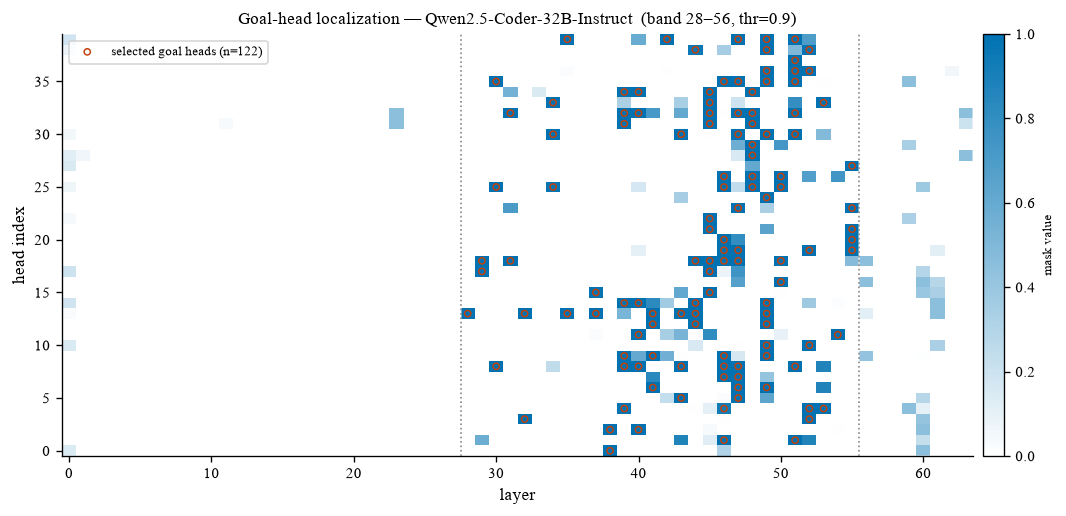

In [2]:
# heatmap: mask value over (layer x head); band shaded; selected heads outlined
fig,ax=plt.subplots(figsize=(9,4.4))
cmap=LinearSegmentedColormap.from_list('goal',['white',F.MODEL_COLOR[SLUG]],N=256); cmap.set_bad('#EFEFEF')
im=ax.imshow(np.ma.masked_invalid(GRID.T),cmap=cmap,aspect='auto',vmin=0,vmax=1,
             interpolation='nearest',origin='lower')
# grey veil outside the band
ax.axvspan(-0.5,BAND[0]-0.5,color='white',alpha=0.55,zorder=2)
ax.axvspan(BAND[1]-0.5,N_LAYER-0.5,color='white',alpha=0.55,zorder=2)
for xb in (BAND[0]-0.5,BAND[1]-0.5): ax.axvline(xb,color='#888',ls=':',lw=1,zorder=3)
# outline selected heads
sx=[l for l,h in SEL]; sy=[h for l,h in SEL]
ax.scatter(sx,sy,s=14,facecolors='none',edgecolors='#c2410c',linewidths=0.9,zorder=4,
           label=f'selected goal heads (n={len(SEL)})')
ax.set_xlabel('layer'); ax.set_ylabel('head index'); ax.set_ylim(-0.5,N_HEAD-0.5)
ax.set_title(f'Goal-head localization — {SLUG}  (band {BAND[0]}–{BAND[1]}, thr={THR})',fontsize=10)
ax.legend(fontsize=8,frameon=True,loc='upper left')
cb=fig.colorbar(im,ax=ax,fraction=0.025,pad=0.01); cb.set_label('mask value',fontsize=8)
ax.grid(False)
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'head_localization_map')); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/head_localization/goal_heads_per_layer.pdf


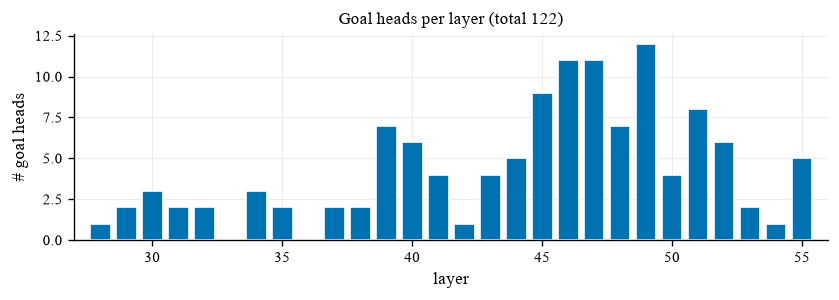

In [3]:
# per-layer count of selected goal heads (compact companion bar)
from collections import Counter
cnt=Counter(l for l,h in SEL); xs=sorted(cnt)
fig,ax=plt.subplots(figsize=(7,2.6))
ax.bar(xs,[cnt[l] for l in xs],color=F.MODEL_COLOR[SLUG],edgecolor='white')
ax.set_xlabel('layer'); ax.set_ylabel('# goal heads'); ax.set_xlim(BAND[0]-1,BAND[1])
ax.set_title(f'Goal heads per layer (total {len(SEL)})',fontsize=10)
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'goal_heads_per_layer')); plt.show()